![image.png](https://i.imgur.com/a3uAqnb.png)

# Fine-Tuning With LoRA and QLoRA: Voice-Assistant Requests to JSON

- **Dataset**: [Amazon MASSIVE](https://huggingface.co/datasets/AmazonScience/massive), requests people said to a voice assistant, each labelled with an intent and with slots (the time, the place, the song...). The same requests exist in English and Arabic.
- **Task**: turn a request into JSON such as `{"intent": "alarm_set", "slots": {"time": "nine am", "date": "friday"}}`
- **Model**: [Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B) with LoRA, and [Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B) with QLoRA
- **Runtime**: Colab T4 GPU, about 20 minutes of compute

In this lab, we will:

- score a frozen model on the task, in English and in Arabic
- count the parameters LoRA trains, by hand and with PEFT
- fine-tune with TRL's `SFTTrainer`, with the loss on the answer only, and score again
- check what else the adapter changed, and turn it off
- fine-tune a larger model in 4 bits (QLoRA) and compare GPU memory
- save the adapter and merge it into the model

This notebook is adapted from the *Supervised Fine-Tuning* and *PEFT* labs prepared by Lama for the KAUST Academy NLP course.

## LoRA in brief

Full fine-tuning updates every weight matrix $W$. LoRA keeps $W$ frozen and learns a low-rank change:

$$h = W x + \frac{\alpha}{r} B A x$$

Where:
- $W$ is a frozen $d \times k$ weight matrix, $x$ its input and $h$ its output
- $A$ is $r \times k$ and $B$ is $d \times r$; only they are trained, and $B$ starts at zero so training starts from the original model
- $r$ is the rank (8 to 64 is common) and $\alpha / r$ scales the update

A matrix of $d \times k$ weights gets $r(d + k)$ trainable ones. **QLoRA** stores the frozen $W$ in 4 bits and keeps $A$ and $B$ in 16 or 32 bits, so larger models fit in GPU memory.

## Setup

In Google Colab, select **Runtime > Change runtime type > T4 GPU**, then run the cells from top to bottom. The next cell installs TRL (the training library) and bitsandbytes (4-bit loading).

In [1]:
%pip install -q trl bitsandbytes
# an older torchao preinstalled on Colab makes PEFT fail to import; this lab does not use torchao
%pip uninstall -q -y torchao

In [2]:
import json
import os
import random
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from transformers.utils import logging as hf_logging
from trl import SFTConfig, SFTTrainer

hf_logging.set_verbosity_error()   # hide informational warnings from model loading and training

Every size and model name lives in the next cell. `N_TRAIN` sets how many training requests each intent contributes per language, and `N_TEST` how many test requests.

In [3]:
SEED = 42
MODEL_ID = "Qwen/Qwen3-0.6B"           # trained with LoRA
QLORA_MODEL_ID = "Qwen/Qwen3-1.7B"     # trained with QLoRA in section 8
INTENTS = ["alarm_set", "weather_query", "play_music", "calendar_set", "news_query", "email_sendemail",
           "cooking_recipe", "transport_query", "datetime_query", "iot_hue_lightoff"]
LANGS = ["en-US", "ar-SA"]
N_TRAIN = 40    # per language: 40 x 10 x 2 = 800 training requests
N_TEST = 10     # per language: 100 test requests in English and 100 in Arabic
LORA_R = 16
EPOCHS = 2
BATCH_SIZE = 8
LEARNING_RATE = 2e-4
MAX_NEW_TOKENS = 64

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = DEVICE == "cuda" and torch.cuda.get_device_capability(0)[0] >= 8   # a T4 (7.5) has no bfloat16
FP16 = DEVICE == "cuda" and not BF16
DTYPE = torch.bfloat16 if BF16 else torch.float16 if FP16 else torch.float32
print(f"PyTorch {torch.__version__} | device: {DEVICE} | weights in {DTYPE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")

PyTorch 2.14.1+cu130 | device: cuda | weights in torch.float16
GPU: Tesla T4 (15.6 GB)


## 1. The data: requests with intents and slots

MASSIVE marks each slot inside the request, as in `wake me up at [time : nine am] on [date : friday]`. We turn those marks into a dictionary, and the dictionary plus the intent into the JSON answer the model must learn to write. The parquet files load without any dataset script.

In [4]:
BASE = "hf://datasets/AmazonScience/massive@refs%2Fconvert%2Fparquet"
SLOT = re.compile(r"\[([^:\]]+?)\s*:\s*([^\]]+?)\]")


def to_json(row, names):
    slots = {k.strip(): v.strip() for k, v in SLOT.findall(row["annot_utt"])}
    return json.dumps({"intent": names.int2str(row["intent"]), "slots": slots}, ensure_ascii=False)


data = {}
for lang in LANGS:
    ds = load_dataset("parquet", data_files={s: f"{BASE}/{lang}/{s}/0000.parquet" for s in ["train", "test"]})
    names = ds["train"].features["intent"]
    keep = [names.str2int(i) for i in INTENTS]
    for split in ["train", "test"]:
        rows = [r for r in ds[split] if r["intent"] in keep]
        per = N_TRAIN if split == "train" else N_TEST
        rng = random.Random(SEED)
        picked = []
        for i in keep:
            group = [r for r in rows if r["intent"] == i]
            picked += rng.sample(group, min(per, len(group)))
        data[lang, split] = [{"text": r["utt"], "answer": to_json(r, names), "lang": lang} for r in picked]

for lang in LANGS:
    print(lang, "train:", len(data[lang, "train"]), "test:", len(data[lang, "test"]))
    for ex in data[lang, "train"][:2]:
        print("  ", ex["text"], "->", ex["answer"])

0000.parquet:   0%|          | 0.00/676k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/191k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

0000.parquet:   0%|          | 0.00/860k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/235k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

en-US train: 400 test: 100
   set alarm for saturday morning soccer practice at eight am -> {"intent": "alarm_set", "slots": {"date": "saturday", "timeofday": "morning", "event_name": "soccer practice", "time": "eight am"}}
   set the alarm tone -> {"intent": "alarm_set", "slots": {}}
ar-SA train: 400 test: 100
   حط منبه على ثمنية الصباح يوم السبت عشان تدريب الكورة -> {"intent": "alarm_set", "slots": {"time": "ثمنية الصباح", "date": "السبت", "event_name": "تدريب الكورة"}}
   اضبط نغمة المنبه -> {"intent": "alarm_set", "slots": {}}


The instruction tells the model the format and the allowed intents. The same short instruction is used before and after training, so any gain comes from training, not from a better prompt.

In [5]:
SYSTEM = ("Turn the user's request to a voice assistant into JSON with two keys: \"intent\", one of "
          + ", ".join(INTENTS) + ", and \"slots\", a dictionary of the details in the request "
          "(for example time, date, place_name). Answer with the JSON only.")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)


def render(text, tok=tokenizer):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": text}]
    return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)


print(render(data["en-US", "train"][0]["text"]))

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

<|im_start|>system
Turn the user's request to a voice assistant into JSON with two keys: "intent", one of alarm_set, weather_query, play_music, calendar_set, news_query, email_sendemail, cooking_recipe, transport_query, datetime_query, iot_hue_lightoff, and "slots", a dictionary of the details in the request (for example time, date, place_name). Answer with the JSON only.<|im_end|>
<|im_start|>user
set alarm for saturday morning soccer practice at eight am<|im_end|>
<|im_start|>assistant
<think>

</think>




## 2. The scorer

Three numbers per language: how many answers parse as JSON, how many have the right intent, and how many match the reference exactly (intent and every slot, ignoring case). Generation is greedy, so a score changes only when the model changes.

In [6]:
def parse(text):
    try:
        start = text.index("{")
        obj, _ = json.JSONDecoder().raw_decode(text[start:])
        return obj if isinstance(obj, dict) else None
    except ValueError:
        return None


def norm(slots):
    return {str(k).lower().strip(): str(v).lower().strip() for k, v in slots.items()} if isinstance(slots, dict) else {}


@torch.no_grad()
def generate(model, tok, prompts, max_new_tokens=MAX_NEW_TOKENS, batch_size=16):
    tok.padding_side = "left"
    outs = []
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs


def score(model, tok=tokenizer, name=""):
    rows = {}
    for lang in LANGS:
        test = data[lang, "test"]
        preds = [parse(o) for o in generate(model, tok, [render(r["text"], tok) for r in test])]
        gold = [json.loads(r["answer"]) for r in test]
        rows[lang] = {
            "valid JSON": np.mean([p is not None for p in preds]),
            "intent": np.mean([p is not None and p.get("intent") == g["intent"] for p, g in zip(preds, gold)]),
            "exact": np.mean([p is not None and p.get("intent") == g["intent"] and norm(p.get("slots")) == norm(g["slots"])
                              for p, g in zip(preds, gold)]),
        }
    table = pd.DataFrame(rows).T.round(3)
    table.index.name = name
    return table

## 3. The frozen model

First the model as it is, with the instruction only. This is the number fine-tuning must beat.

In [7]:
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE)
model.eval()
before = score(model, name="frozen")
before

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,valid JSON,intent,exact
frozen,,,
en-US,0.97,0.62,0.02
ar-SA,0.99,0.59,0.00


Look at a few answers in Arabic: the format, the intent names and the slot names are where a frozen model slips.

In [8]:
sample = data["ar-SA", "test"][:3]
for r, out in zip(sample, generate(model, tokenizer, [render(r["text"]) for r in sample])):
    print(r["text"], "\n  model:", out.strip()[:150], "\n  gold: ", r["answer"], "\n")

حط منبه للإجتماع مع بدر الساعة سبعة اليوم 
  model: {
  "intent": "alarm_set",
  "slots": {
    "time": "7:00",
    "date": "today",
    "place_name": "meeting with Dr. B"
  }
} 
  gold:  {"intent": "alarm_set", "slots": {"event_name": "للإجتماع", "person": "بدر", "time": "سبعة", "date": "اليوم"}} 

حط منبه بس ليوم الإثنين الساعة ستة الصبح 
  model: {
  "intent": "alarm_set",
  "slots": {
    "time": "sixth hour",
    "date": "Tuesday",
    "place_name": "Tuesday"
  }
} 
  gold:  {"intent": "alarm_set", "slots": {"date": "الإثنين", "time": "ستة الصبح"}} 

حط منبه يصحيني سبعة الصبح يوم الخميس 
  model: {
  "intent": "alarm_set",
  "slots": {
    "time": "ساعة 7:00",
    "date": "يوم الخميس",
    "place_name": "الساحة"
  }
} 
  gold:  {"intent": "alarm_set", "slots": {"time": "سبعة الصبح", "date": "الخميس"}} 



## 4. LoRA: count what it trains

Qwen3-0.6B has hidden size 1024, 16 query heads and 8 key-value heads of size 128, and a feed-forward size of 3072. The next cell counts the LoRA parameters of one layer by hand, then lets PEFT count the whole model.

In [9]:
shapes = {"q_proj": (1024, 2048), "k_proj": (1024, 1024), "v_proj": (1024, 1024), "o_proj": (2048, 1024),
          "gate_proj": (1024, 3072), "up_proj": (1024, 3072), "down_proj": (3072, 1024)}
per_layer = {name: LORA_R * (k + d) for name, (k, d) in shapes.items()}
print("LoRA parameters in one layer:", per_layer, "| total:", sum(per_layer.values()))
print("x 28 layers =", 28 * sum(per_layer.values()))

lora_config = LoraConfig(r=LORA_R, lora_alpha=2 * LORA_R, lora_dropout=0.05,
                         target_modules="all-linear", task_type="CAUSAL_LM")
peft_model = get_peft_model(model, lora_config)
peft_model.print_trainable_parameters()

LoRA parameters in one layer: {'q_proj': 49152, 'k_proj': 32768, 'v_proj': 32768, 'o_proj': 49152, 'gate_proj': 65536, 'up_proj': 65536, 'down_proj': 65536} | total: 360448
x 28 layers = 10092544
trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


## 5. Supervised fine-tuning with TRL

Each training row has a `prompt` (the rendered conversation, ending where the assistant starts) and a `completion` (the JSON answer and the end-of-turn token). With this format, `SFTTrainer` computes the loss on the completion only.

In [10]:
train_rows = [{"prompt": render(r["text"]), "completion": r["answer"] + "<|im_end|>"}
              for lang in LANGS for r in data[lang, "train"]]
random.Random(SEED).shuffle(train_rows)
train_ds = Dataset.from_list(train_rows)

args = SFTConfig(output_dir="sft-lora", num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH_SIZE,
                 learning_rate=LEARNING_RATE, warmup_steps=0.05, lr_scheduler_type="linear", logging_steps=10,
                 max_length=256, save_strategy="no", report_to="none", seed=SEED, fp16=FP16, bf16=BF16,
                 use_cpu=DEVICE == "cpu")
trainer = SFTTrainer(model=peft_model, args=args, train_dataset=train_ds, processing_class=tokenizer)

Adding EOS to train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Before training, check which tokens carry the loss: the labels are $-100$ (ignored) everywhere except the answer.

In [11]:
row = trainer.train_dataset[0]
print(tokenizer.decode([t for t, l in zip(row["input_ids"], row["labels"]) if l != -100]))

{"intent": "datetime_query", "slots": {"time": "لعز الظهر"}}<|im_end|>


In [12]:
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
start = time.time()
trainer.train()
lora_seconds = time.time() - start
lora_peak = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else float("nan")
print(f"training took {lora_seconds:.0f} s | peak GPU memory {lora_peak:.2f} GB")

{'loss': '0.5974', 'grad_norm': '2.79', 'learning_rate': '0.00018', 'entropy': '0.2465', 'mean_token_accuracy': '0.8636', 'num_tokens': '1.035e+04', 'epoch': '0.1'}
{'loss': '0.2942', 'grad_norm': '2.23', 'learning_rate': '0.0001905', 'entropy': '0.3135', 'mean_token_accuracy': '0.9237', 'num_tokens': '2.064e+04', 'epoch': '0.2'}
{'loss': '0.2632', 'grad_norm': '1.454', 'learning_rate': '0.00018', 'entropy': '0.279', 'mean_token_accuracy': '0.9326', 'num_tokens': '3.113e+04', 'epoch': '0.3'}
{'loss': '0.2457', 'grad_norm': '1.525', 'learning_rate': '0.0001695', 'entropy': '0.2103', 'mean_token_accuracy': '0.9319', 'num_tokens': '4.157e+04', 'epoch': '0.4'}
{'loss': '0.1723', 'grad_norm': '1.147', 'learning_rate': '0.0001589', 'entropy': '0.1561', 'mean_token_accuracy': '0.9558', 'num_tokens': '5.196e+04', 'epoch': '0.5'}
{'loss': '0.1827', 'grad_norm': '1.67', 'learning_rate': '0.0001484', 'entropy': '0.1791', 'mean_token_accuracy': '0.9528', 'num_tokens': '6.232e+04', 'epoch': '0.6'}


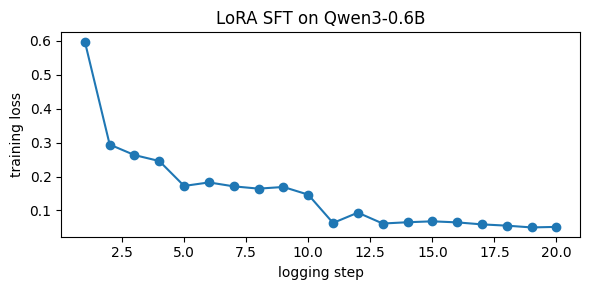

In [13]:
losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]
plt.figure(figsize=(6, 3))
plt.plot(range(1, len(losses) + 1), losses, marker="o")
plt.xlabel("logging step")
plt.ylabel("training loss")
plt.title("LoRA SFT on Qwen3-0.6B")
plt.tight_layout()
plt.show()

## 6. Before and after

The same test requests, the same instruction, the same scorer.

In [14]:
peft_model.eval()
after = score(peft_model, name="LoRA")
pd.concat({"frozen": before, "LoRA": after}, axis=1)

frozen                    LoRA             
      valid JSON intent exact valid JSON intent exact
en-US       0.97   0.62  0.02        1.0   0.95  0.64
ar-SA       0.99   0.59  0.00        1.0   0.88  0.42

## 7. What else did the adapter change?

Every training answer was JSON. Ask a few ordinary questions without the system message, once with the adapter and once with it turned off. `disable_adapter()` runs the original model without reloading anything.

In [15]:
GENERAL = ["What is the capital of Japan?", "Give me one tip for a job interview.", "Write a two-line poem about the sea."]


def plain(q):
    return tokenizer.apply_chat_template([{"role": "user", "content": q}], tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)


with_adapter = generate(peft_model, tokenizer, [plain(q) for q in GENERAL], 48)
with peft_model.disable_adapter():
    without = generate(peft_model, tokenizer, [plain(q) for q in GENERAL], 48)
for q, a, b in zip(GENERAL, with_adapter, without):
    print(q, "\n  adapter on: ", a.strip()[:120], "\n  adapter off:", b.strip()[:120], "\n")

What is the capital of Japan? 
  adapter on:  The capital of Japan is Tokyo. 
  adapter off: The capital of Japan is **Osaka City**. 

Give me one tip for a job interview. 
  adapter on:  One tip for a job interview is to be prepared and confident. This helps you stand out and demonstrate your skills and en 
  adapter off: One effective tip for a job interview is to **practice your answers confidently and clearly**. This helps you showcase y 

Write a two-line poem about the sea. 
  adapter on:  The sea whispers secrets to the shore,  
A vast, endless blue where dreams are born. 
  adapter off: The waves whisper secrets to the shore,  
And the sea holds its breath in silent song. 



## 8. QLoRA: a larger model in 4 bits

A 1.7B model in 16 bits needs about 3.4 GB for its weights alone. QLoRA loads it in 4-bit NF4 and trains the same kind of adapter. We record GPU memory for both runs. This section needs a GPU (bitsandbytes 4-bit runs on CUDA).

In [16]:
del trainer, peft_model, model
if DEVICE == "cuda":
    torch.cuda.empty_cache()

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                         bnb_4bit_compute_dtype=DTYPE)
q_tokenizer = AutoTokenizer.from_pretrained(QLORA_MODEL_ID)
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
q_model = AutoModelForCausalLM.from_pretrained(QLORA_MODEL_ID, quantization_config=bnb, device_map={"": 0})
print(f"4-bit weights in memory: {q_model.get_memory_footprint() / 1e9:.2f} GB")
q_model = prepare_model_for_kbit_training(q_model)
q_model = get_peft_model(q_model, LoraConfig(r=LORA_R, lora_alpha=2 * LORA_R, lora_dropout=0.05,
                                             target_modules="all-linear", task_type="CAUSAL_LM"))
q_model.print_trainable_parameters()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

4-bit weights in memory: 1.33 GB
trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


In [17]:
q_train = [{"prompt": render(r["text"], q_tokenizer), "completion": r["answer"] + "<|im_end|>"}
           for lang in LANGS for r in data[lang, "train"]]
random.Random(SEED).shuffle(q_train)
q_args = SFTConfig(output_dir="sft-qlora", num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH_SIZE,
                   learning_rate=LEARNING_RATE, warmup_steps=0.05, logging_steps=10, max_length=256,
                   save_strategy="no", report_to="none", seed=SEED, fp16=FP16, bf16=BF16)
q_trainer = SFTTrainer(model=q_model, args=q_args, train_dataset=Dataset.from_list(q_train),
                       processing_class=q_tokenizer)
if FP16:   # TRL stores the QLoRA adapter in bfloat16, which fp16 training on a T4 cannot use
    for p in q_model.parameters():
        if p.requires_grad:
            p.data = p.data.float()
start = time.time()
q_trainer.train()
qlora_seconds = time.time() - start
qlora_peak = torch.cuda.max_memory_allocated() / 1e9
print(f"training took {qlora_seconds:.0f} s | peak GPU memory {qlora_peak:.2f} GB")

Adding EOS to train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

{'loss': '0.9185', 'grad_norm': '2.715', 'learning_rate': '0.00018', 'entropy': '0.09238', 'mean_token_accuracy': '0.8764', 'num_tokens': '1.035e+04', 'epoch': '0.1'}
{'loss': '0.3106', 'grad_norm': '1.442', 'learning_rate': '0.0001905', 'entropy': '0.2559', 'mean_token_accuracy': '0.931', 'num_tokens': '2.064e+04', 'epoch': '0.2'}
{'loss': '0.2257', 'grad_norm': '1.368', 'learning_rate': '0.00018', 'entropy': '0.2289', 'mean_token_accuracy': '0.936', 'num_tokens': '3.113e+04', 'epoch': '0.3'}
{'loss': '0.1762', 'grad_norm': '0.6738', 'learning_rate': '0.0001695', 'entropy': '0.1593', 'mean_token_accuracy': '0.9462', 'num_tokens': '4.157e+04', 'epoch': '0.4'}
{'loss': '0.1497', 'grad_norm': '0.7223', 'learning_rate': '0.0001589', 'entropy': '0.1241', 'mean_token_accuracy': '0.9583', 'num_tokens': '5.196e+04', 'epoch': '0.5'}
{'loss': '0.1224', 'grad_norm': '0.6616', 'learning_rate': '0.0001484', 'entropy': '0.1242', 'mean_token_accuracy': '0.963', 'num_tokens': '6.232e+04', 'epoch': '0

In [18]:
q_model.eval()
qlora_after = score(q_model, q_tokenizer, name="QLoRA")
pd.concat({"frozen 0.6B": before, "LoRA 0.6B": after, "QLoRA 1.7B": qlora_after}, axis=1)

frozen 0.6B               LoRA 0.6B              QLoRA 1.7B             
       valid JSON intent exact valid JSON intent exact valid JSON intent exact
en-US        0.97   0.62  0.02        1.0   0.95  0.64        1.0   0.94  0.67
ar-SA        0.99   0.59  0.00        1.0   0.88  0.42        1.0   0.92  0.49

In [19]:
pd.DataFrame({"model": [MODEL_ID, QLORA_MODEL_ID], "method": ["LoRA, 16-bit base", "QLoRA, 4-bit base"],
              "peak GPU memory (GB)": [round(lora_peak, 2), round(qlora_peak, 2)],
              "training time (s)": [round(lora_seconds), round(qlora_seconds)]})

,model,method,peak GPU memory (GB),training time (s)
0,Qwen/Qwen3-0.6B,"LoRA, 16-bit base",1.60,139
1,Qwen/Qwen3-1.7B,"QLoRA, 4-bit base",2.88,283


## 9. Save the adapter, or merge it

`save_pretrained` on a PEFT model writes only the adapter. To get one ordinary model, load the base in 16 bits, attach the adapter and call `merge_and_unload()`, which returns a new model with $\frac{\alpha}{r}BA$ added into each $W$.

In [20]:
q_model.save_pretrained("qlora-adapter")
size_mb = sum(os.path.getsize(os.path.join("qlora-adapter", f)) for f in os.listdir("qlora-adapter")) / 1e6
print(f"adapter folder: {size_mb:.1f} MB")

base16 = AutoModelForCausalLM.from_pretrained(QLORA_MODEL_ID, dtype=DTYPE).to(DEVICE)
merged = PeftModel.from_pretrained(base16, "qlora-adapter").merge_and_unload()
merged.save_pretrained("merged-model")
q_tokenizer.save_pretrained("merged-model")
score(merged.eval(), q_tokenizer, name="merged")

adapter folder: 69.8 MB


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,valid JSON,intent,exact
merged,,,
en-US,1.0,0.96,0.68
ar-SA,1.0,0.89,0.42


The merged folder is an ordinary model: it loads with `AutoModelForCausalLM`, converts to GGUF and serves with Ollama or vLLM like any downloaded model.

Compare the merged scores with the QLoRA scores above. They are close but not identical: the adapter was trained on top of the 4-bit weights, and it is now added to the 16-bit ones. Score the merged model again before you ship it.

## Summary

- A short instruction and a frozen small model leave many answers in the wrong format or with the wrong slots, especially in Arabic.
- LoRA trains small matrices beside the frozen weights; their number follows from $r(d + k)$ per matrix and matches PEFT's count.
- With the loss on the answer only, `SFTTrainer` teaches the format, the intent names and the slot names from a few hundred examples.
- The adapter can change answers outside its task; turning it off restores the original model.
- QLoRA trains a larger model with a 4-bit base; merging the adapter gives one ordinary model to ship.

## Exercises

1. Set `LORA_R` to 4 and to 64 and retrain. How do the trainable parameters and the scores change?
2. Train on English requests only and score both languages. How much of the Arabic gain comes from the Arabic training data?
3. Set `N_TRAIN` to 5 and to 100. Plot exact match against the number of training requests.
4. Change `QLORA_MODEL_ID` to `"Qwen/Qwen3-4B"`. Does it still fit on the T4, and what does the larger model gain?

## Further Reading

- [Hu et al., 2021. LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685)
- [Dettmers et al., 2023. QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314)
- [Hugging Face TRL: SFT Trainer](https://huggingface.co/docs/trl/sft_trainer)
- [Hugging Face PEFT: LoRA](https://huggingface.co/docs/peft/developer_guides/lora)
- [FitzGerald et al., 2022. MASSIVE: A 1M-Example Multilingual Natural Language Understanding Dataset with 51 Typologically-Diverse Languages](https://arxiv.org/abs/2204.08582)

### Contributed by: Yazan Alshoibi